
 STEP 1: HARDWARE SETUP
-> Selected Device: CPU
-> Optimization: Apple M4 Chip (Metal Performance Shaders), 24GB RAM available.
[Step 1 completed in 0.001 seconds]

 STEP 2: DATA LOADING & PREPARATION
-> Reading dataset index from ../data/PTB-XL/ptbxl_database.csv...
-> Loading 20000 patient records into memory...
-> Converting data lists to PyTorch Tensors...
   [!] Input History Shape: torch.Size([20000, 12, 500])  -> [Patients, Leads, Time Steps]
   [!] Target Future Shape: torch.Size([20000, 12, 300])  -> [Patients, Leads, Time Steps]
-> Creating DataLoader (Batch size = 32)...
[Step 2 completed in 49.21 seconds]

 STEP 3: INITIALIZING NEURAL NETWORK
-> Model built and sent to M4 GPU.
[Step 3 completed in 0.008 seconds]

 STEP 4: TRAINING LOOP
-> Epoch [1/10] | Processed 625 batches | Average Loss: 0.0494 | Time: 112.59s
-> Epoch [2/10] | Processed 625 batches | Average Loss: 0.0487 | Time: 101.43s
-> Epoch [3/10] | Processed 625 batches | Average Loss: 0.0482 | Time: 128.96s
-> E

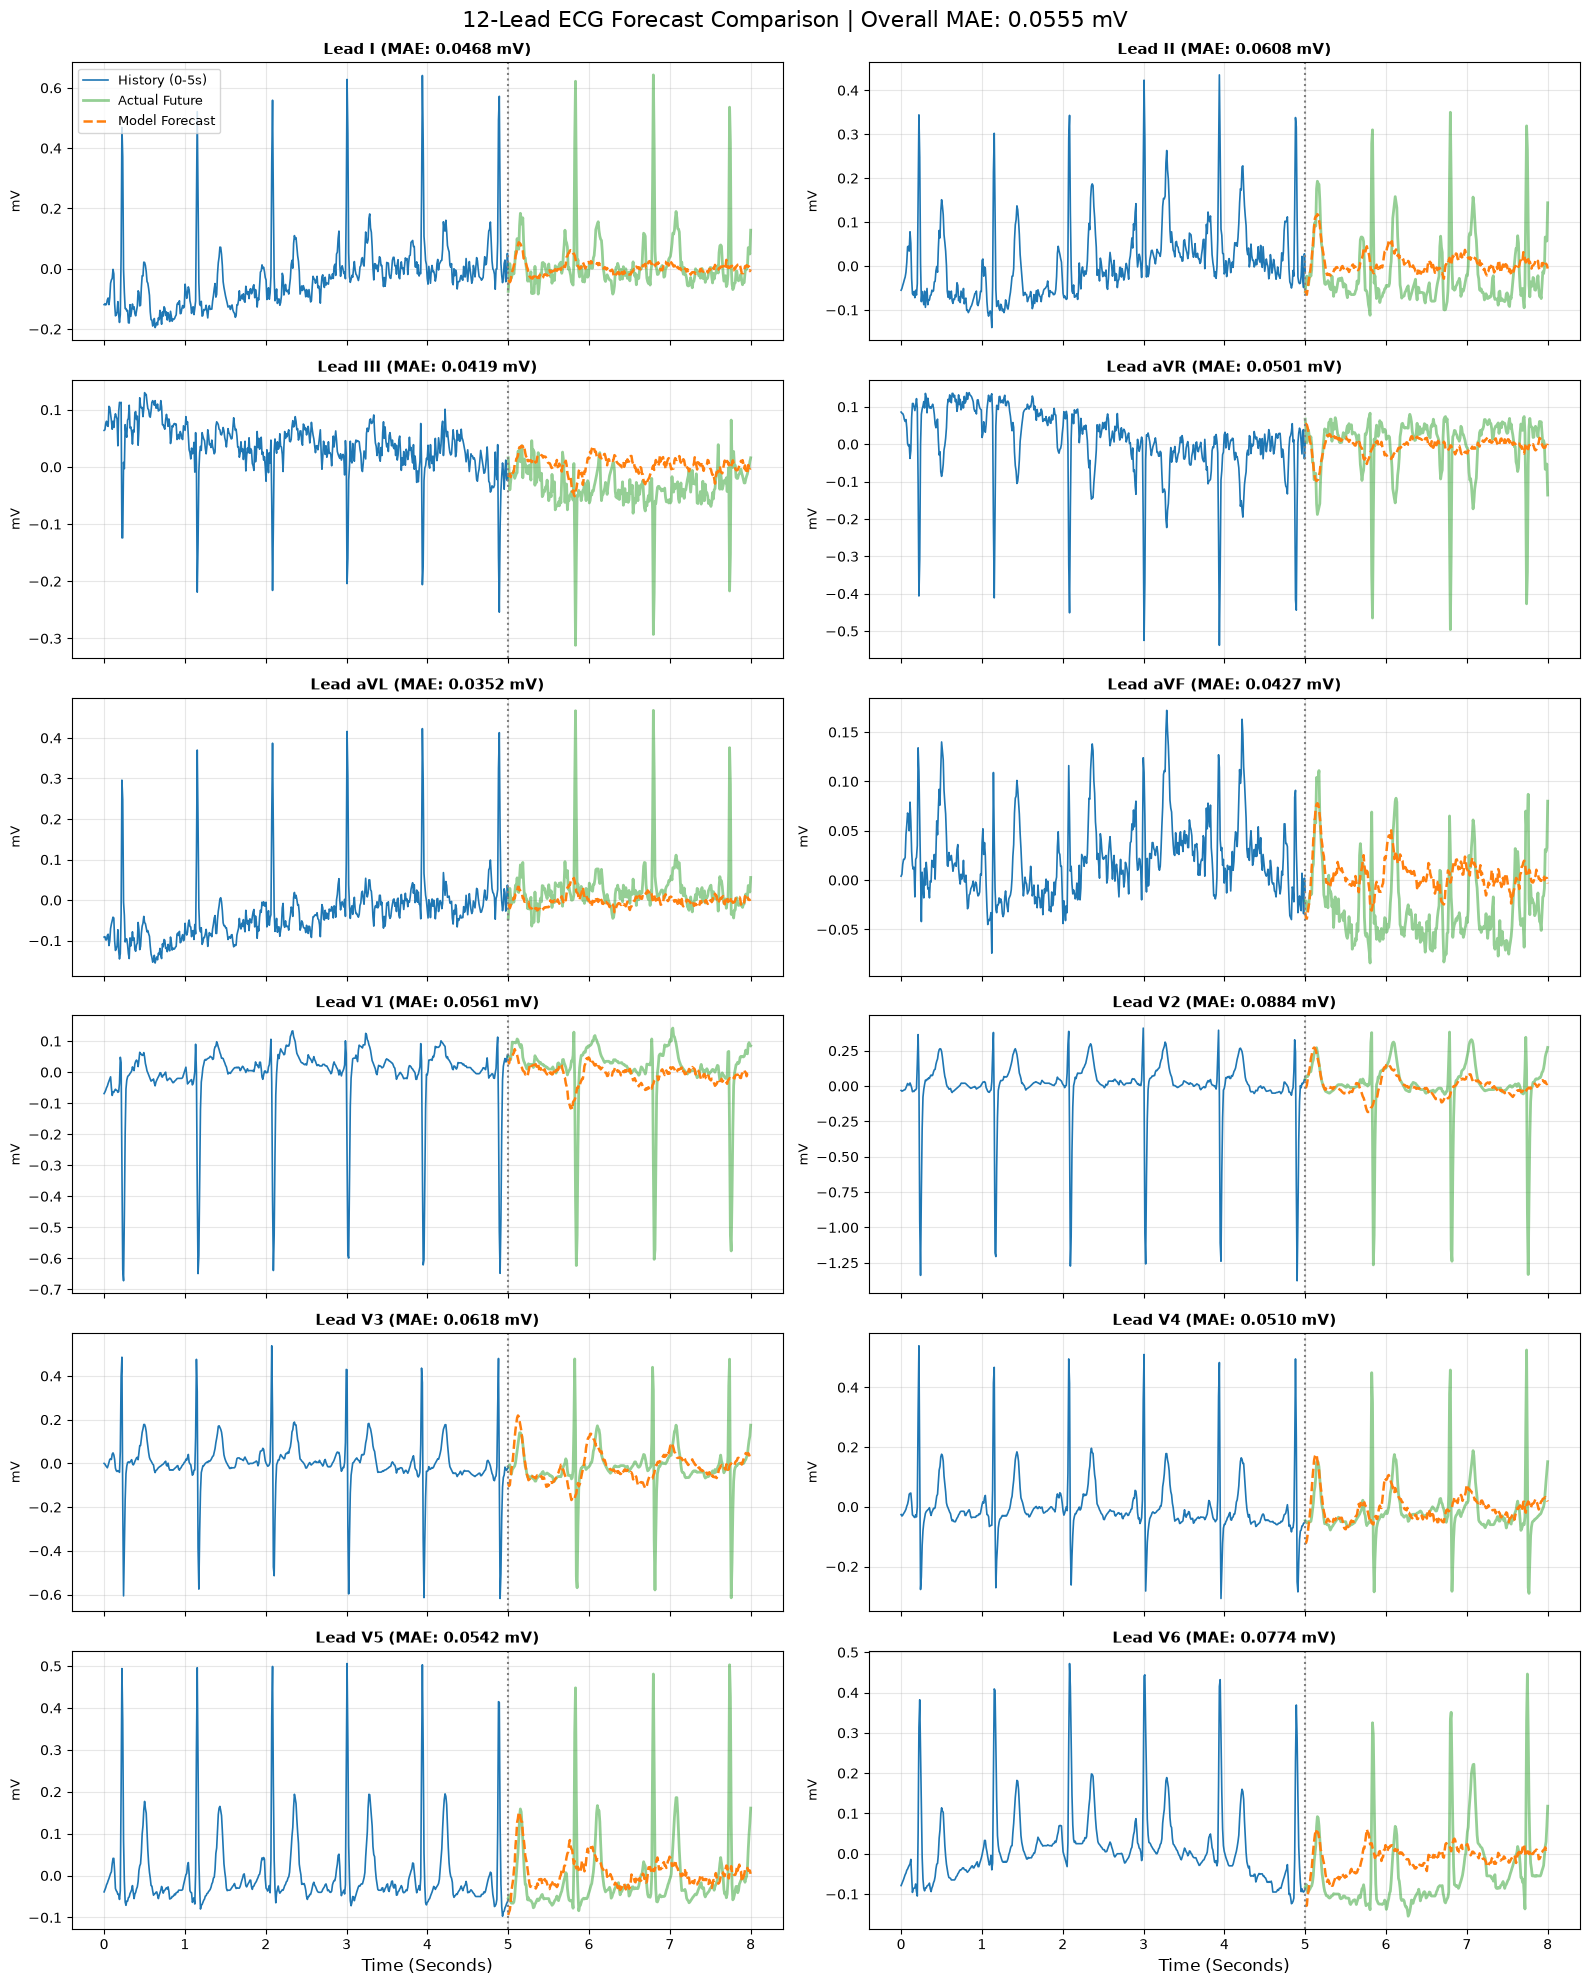

-> Plot saved to 'cnn_lstm_12lead_comparison_final.pdf'
[Step 5 completed in 0.90 seconds]

=== PIPELINE FINISHED SUCCESSFULLY ===


In [11]:
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import numpy as np
import pandas as pd
import wfdb
import matplotlib.pyplot as plt

# ==========================================
# 1. HARDWARE SETUP
# ==========================================
print("\n" + "="*50)
print(" STEP 1: HARDWARE SETUP")
print("="*50)
start_step1 = time.time()

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"-> Selected Device: {device.type.upper()}")
print("-> Optimization: Apple M4 Chip (Metal Performance Shaders), 24GB RAM available.")

print(f"[Step 1 completed in {time.time() - start_step1:.3f} seconds]")

# ==========================================
# 2. LOAD 100 HZ DATA (ALL 12 LEADS)
# ==========================================
print("\n" + "="*50)
print(" STEP 2: DATA LOADING & PREPARATION")
print("="*50)
start_step2 = time.time()

DATA_PATH = '../data/PTB-XL/'
NUM_SAMPLES = 20000

print(f"-> Reading dataset index from {DATA_PATH}ptbxl_database.csv...")
try:
    df = pd.read_csv(os.path.join(DATA_PATH, 'ptbxl_database.csv'), index_col='ecg_id')
except FileNotFoundError:
    print(f"ERROR: Cannot find ptbxl_database.csv in {DATA_PATH}. Please check your folder structure.")
    raise

df_subset = df.head(NUM_SAMPLES)

print(f"-> Loading {NUM_SAMPLES} patient records into memory...")
X_list, Y_list = [], []

for idx, row in df_subset.iterrows():
    full_path = os.path.join(DATA_PATH, row['filename_lr'])
    signal, meta = wfdb.rdsamp(full_path)
    signal = signal.T # Transpose: shape becomes [12 leads, 1000 time steps]
    
    # Split: 0-5s History (500 steps), 5-8s Future (300 steps)
    X_list.append(signal[:, 0:500])
    Y_list.append(signal[:, 500:800])

print("-> Converting data lists to PyTorch Tensors...")
X_tensor = torch.tensor(np.array(X_list), dtype=torch.float32) 
Y_tensor = torch.tensor(np.array(Y_list), dtype=torch.float32) 

print(f"   [!] Input History Shape: {X_tensor.shape}  -> [Patients, Leads, Time Steps]")
print(f"   [!] Target Future Shape: {Y_tensor.shape}  -> [Patients, Leads, Time Steps]")

print("-> Creating DataLoader (Batch size = 32)...")
dataset = TensorDataset(X_tensor, Y_tensor)
dataloader = DataLoader(dataset, batch_size=32, shuffle=True)

print(f"[Step 2 completed in {time.time() - start_step2:.2f} seconds]")

# ==========================================
# 3. SIMPLE HYBRID CNN-LSTM ARCHITECTURE
# ==========================================
print("\n" + "="*50)
print(" STEP 3: INITIALIZING NEURAL NETWORK")
print("="*50)
start_step3 = time.time()

class SimpleHybridModel(nn.Module):
    def __init__(self):
        super(SimpleHybridModel, self).__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(in_channels=12, out_channels=32, kernel_size=7, padding=3), 
            nn.ReLU(),
            nn.AvgPool1d(kernel_size=2, stride=2), 
            nn.Conv1d(in_channels=32, out_channels=64, kernel_size=3, padding=1), 
            nn.ReLU()
        )
        self.lstm = nn.LSTM(input_size=64, hidden_size=128, num_layers=2, batch_first=True)
        self.forecast_head = nn.Linear(in_features=128, out_features=12 * 300)

    def forward(self, x):
        batch_size = x.size(0)
        
        # Pass through CNN
        cnn_out = self.cnn(x)
        
        # Reshape for LSTM: [Batch, Channels, Time] -> [Batch, Time, Channels]
        lstm_input = cnn_out.permute(0, 2, 1)
        
        # Pass through LSTM
        lstm_output, _ = self.lstm(lstm_input)
        
        # Take the last hidden state
        final_hidden_state = lstm_output[:, -1, :]
        
        # Project to future forecast and reshape to [Batch, 12, 300]
        flat_forecast = self.forecast_head(final_hidden_state)
        return flat_forecast.view(batch_size, 12, 300)

model = SimpleHybridModel().to(device)
criterion = nn.MSELoss() 
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("-> Model built and sent to M4 GPU.")
print(f"[Step 3 completed in {time.time() - start_step3:.3f} seconds]")

# ==========================================
# 4. RUN TRAINING
# ==========================================
print("\n" + "="*50)
print(" STEP 4: TRAINING LOOP")
print("="*50)
total_train_start = time.time()

epochs = 10
for epoch in range(epochs):
    epoch_start = time.time()
    model.train()
    total_loss = 0
    batch_count = 0
    
    for batch_X, batch_Y in dataloader:
        batch_count += 1
        
        # Move to GPU
        batch_X = batch_X.to(device)
        batch_Y = batch_Y.to(device)
        
        # Make prediction
        predictions = model(batch_X)
        
        # Calculate Error
        loss = criterion(predictions, batch_Y)
        
        # Backpropagation (Learn)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
    avg_loss = total_loss / len(dataloader)
    epoch_time = time.time() - epoch_start
    print(f"-> Epoch [{epoch+1}/{epochs}] | Processed {batch_count} batches | Average Loss: {avg_loss:.4f} | Time: {epoch_time:.2f}s")

print(f"[Step 4 (All Epochs) completed in {time.time() - total_train_start:.2f} seconds]")

# ==========================================
# 5. 12-LEAD COMPARISON & GRAPHICAL PLOT
# ==========================================
print("\n" + "="*50)
print(" STEP 5: EVALUATION & PLOTTING")
print("="*50)
start_step5 = time.time()

model.eval()

# Pick Patient Index 0 from the loaded batch to evaluate
sample_idx = 0 
test_history = X_tensor[sample_idx:sample_idx+1].to(device)
actual_future = Y_tensor[sample_idx].numpy()

print(f"-> Running inference on patient {sample_idx}...")
inference_start = time.time()
with torch.no_grad():
    predicted_future = model(test_history).cpu().numpy()[0]
print(f"   [Inference took {time.time() - inference_start:.4f} seconds]")

# Calculate MAE
overall_mae = np.mean(np.abs(actual_future - predicted_future))
print(f"-> Overall 12-Lead MAE: {overall_mae:.4f} mV")

print("-> Generating 12-Lead clinical grid plot...")
lead_names = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
time_hist = np.linspace(0, 5, 500)
time_future = np.linspace(5, 8, 300)

fig, axes = plt.subplots(nrows=6, ncols=2, figsize=(16, 20), sharex=True)
axes = axes.flatten()

for i, ax in enumerate(axes):
    history_signal = X_tensor[sample_idx, i, :].numpy()
    actual_signal = actual_future[i, :]
    predicted_signal = predicted_future[i, :]
    
    lead_mae = np.mean(np.abs(actual_signal - predicted_signal))
    
    # Plotting data
    ax.plot(time_hist, history_signal, label="History (0-5s)", color="#1f77b4", linewidth=1.2)
    ax.plot(time_future, actual_signal, label="Actual Future", color="#2ca02c", alpha=0.5, linewidth=2)
    ax.plot(time_future, predicted_signal, label="Model Forecast", color="#ff7f0e", linestyle="--", linewidth=1.8)
    
    # Plot formatting
    ax.axvline(x=5, color='gray', linestyle=':')
    ax.set_title(f"Lead {lead_names[i]} (MAE: {lead_mae:.4f} mV)", fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.set_ylabel("mV", fontsize=9)
    
    # Legend only on the first plot to avoid clutter
    if i == 0: 
        ax.legend(loc="upper left", fontsize=9)

# X-axis labels on the bottom row
for ax in axes[-2:]:
    ax.set_xlabel("Time (Seconds)", fontsize=12)

plt.suptitle(f"12-Lead ECG Forecast Comparison | Overall MAE: {overall_mae:.4f} mV", fontsize=16, y=0.99)
plt.tight_layout()

# Save the plot
plot_filename = "cnn_lstm_12lead_comparison_final.pdf"
plt.savefig(plot_filename, bbox_inches='tight')
plt.show()

print(f"-> Plot saved to '{plot_filename}'")
print(f"[Step 5 completed in {time.time() - start_step5:.2f} seconds]")

print("\n=== PIPELINE FINISHED SUCCESSFULLY ===")